# Valorisation joueurs Big 5 — saison 2025-2026

On essaie de voir si le prix d'un joueur suit ce qu'il a fait sur le terrain.
Sources : FBref (le jeu), Transfermarkt (la cote), SalarySport (salaire et fin de contrat, scrapé), un panel Insta de 100 joueurs pris à la main.

Seuil choisi : les 5 grands championnats, joueurs ayant joué au moins 900 minutes.

## Fichiers choisis

Dans le dossier TM il y avait aussi les matchs, les transferts, les pays.
On n'en choisit que 5, plus le relevé SalarySport :

- `Fbref/all_player_stats.csv` : minutes, buts, passes décisives, tacles, arrêts
- `Fbref/all_player_profiles.csv` : nom, poste, une cote au cas où
- `Transfermarket/players.csv` : qui c'est, quel club, quelle nationalité
- `Transfermarket/player_valuations.csv` : la cote avec une date
- `Transfermarket/clubs.csv` : le nom propre du club
- `salarysport_top5_salaires_contrats.csv` : salaire estimé et fin de contrat, scrapé

`games.csv` concerne les matchs. `transfers.csv` c'est le prix de vente passé, pas le marché maintenant.

## Imports et réglages

In [1]:
import re
import time
import calendar
import unicodedata
from io import StringIO
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)

Les cotes Transfermarkt retenues sont datées pour la plupart de mai-juin 2026. On calculera donc l'âge et les années de contrat restantes à la même date, le 30 juin 2026, fin de saison.

In [2]:
DOSSIER = Path(".") if Path("Fbref").exists() else Path("Sources")
print("dossier des données :", DOSSIER)

ORDRE_LIGUE = ["Premier League", "Serie A", "Ligue 1", "LaLiga", "Bundesliga"]
ORDRE_POSTE = ["F", "M", "D", "G"]
DATE_REF = pd.Timestamp("2026-06-30")
SCRAPER = False   # True : relance le scraping SalarySport ; False : relit le CSV collecté le 07/10/2026

# Validation croisée 
CV5 = KFold(n_splits=5, shuffle=True, random_state=42)

dossier des données : .


## Fonctions

In [3]:
def charger_csv(relatif, sep=",", skiprows=0):
    return pd.read_csv(DOSSIER / relatif, sep=sep, skiprows=skiprows)

In [4]:
# uniformisation noms en minuscule

In [5]:
def norm_nom(s):
    s = str(s).strip().lower()
    s = unicodedata.normalize("NFKD", s)
    s = "".join(c for c in s if not unicodedata.combining(c))
    return " ".join(s.split())

print(norm_nom("  Luka Modrić "), "|", norm_nom("Kylian Mbappé"))

luka modric | kylian mbappe


In [6]:
# Seuil de 900 minutes (en dessous, une stat par 90 minutes ne veut pas dire grand-chose) + uniformisation stats à 90 min

In [7]:
def garder_assez_joue(df, col="fb_minutes", seuil=900):
    return df[df[col] >= seuil].copy()

def stats_par_90(df):
    df["buts_90"] = df["fb_buts"] / df["fb_minutes"] * 90
    df["passes_dec_90"] = df["fb_passes_dec"] / df["fb_minutes"] * 90
    df["tacles_90"] = df["fb_tacles"] / df["fb_minutes"] * 90
    df["inter_90"] = df["fb_interceptions"] / df["fb_minutes"] * 90
    df["arrets_90"] = df["fb_arrets"] / df["fb_minutes"] * 90
    df["xg_90"] = df["fb_xg"] / df["fb_minutes"] * 90
    df["xa_90"] = df["fb_xa"] / df["fb_minutes"] * 90
    return df

In [8]:
# Sur Insta j'ai noté 33,8K ou 2,1M. Conversion en vrai nombre.

In [9]:
def followers_vers_nombre(x):
    if pd.isna(x):
        return np.nan
    s = str(x).strip().upper().replace(" ", "").replace(",", ".")
    if s in ("", "NULL", "NAN", "NONE"):
        return np.nan
    if s.endswith("K"):
        return float(s[:-1]) * 1000
    if s.endswith("M"):
        return float(s[:-1]) * 1_000_000
    return float(s)

In [10]:
# Liste fermée de grands clubs, pour comparaison. On compare le nom exact du club Transfermarkt pour éviter confusion clubs

In [11]:
GRANDS_CLUBS = {
    "Real Madrid", "FC Barcelona", "Atlético de Madrid",
    "Bayern Munich", "Borussia Dortmund",
    "Manchester City", "Liverpool FC", "Arsenal FC", "Chelsea FC", "Manchester United",
    "Inter Milan", "AC Milan", "Juventus FC",
    "Paris Saint-Germain",
}

def est_grand_club(nom):
    return int(str(nom).strip() in GRANDS_CLUBS)

In [12]:
# Tirage au hasard de 100 joueurs, pour montrer que la fonction se relance. Le panel Instagram, lui, sera choisi à la main.

In [13]:
def extraire_panel(df, ligue=None, poste=None, age_min=None, age_max=None, n=100):
    out = df.copy()
    if ligue is not None:
        out = out[out["fb_league"] == ligue]
    if poste is not None:
        out = out[out["fb_position"] == poste]
    if age_min is not None:
        out = out[out["age"] >= age_min]
    if age_max is not None:
        out = out[out["age"] <= age_max]
    if len(out) > n:
        out = out.sample(n=n, random_state=42)
    return out

## Ouverture des fichiers

In [14]:
stats = charger_csv("Fbref/all_player_stats.csv")
profils = charger_csv("Fbref/all_player_profiles.csv")
players = charger_csv("Transfermarket/players.csv")
valuations = charger_csv("Transfermarket/player_valuations.csv")
clubs = charger_csv("Transfermarket/clubs.csv")
for nom, df in [("stats", stats), ("profils", profils), ("players", players), ("valuations", valuations), ("clubs", clubs)]:
    print(nom, df.shape)
print(stats.columns.tolist())

stats (3730, 17)
profils (4588, 5)
players (50149, 26)
valuations (656301, 6)
clubs (796, 17)
['player_id', 'league', 'appearances', 'matches_started', 'minutes_played', 'goals', 'assists', 'expected_goals', 'expected_assists', 'rating', 'total_shots', 'shots_on_target', 'yellow_cards', 'red_cards', 'tackles', 'interceptions', 'saves']


In [15]:
# Si presque aucun id en commun, on ne joindra pas là-dessus.

In [16]:
print("ex FBref :", stats["player_id"].head(3).tolist())
print("ex TM    :", players["player_id"].head(3).tolist())
print("ids des deux côtés :", len(set(stats["player_id"]) & set(players["player_id"])))
print(stats["league"].value_counts())

ex FBref : [804508, 934235, 794839]
ex TM    : [10, 26, 65]
ids des deux côtés : 104
league
LaLiga            513
Serie A           495
Premier League    478
Liga Portugal     459
Eredivisie        455
Ligue 1           447
Super Lig         443
Bundesliga        440
Name: count, dtype: int64


Les id FBref et TM ne se recoupent que sur une centaine de joueurs, et ce ne sont pas les mêmes numérotations. On ne joindra pas dessus. Le fichier stats contient 8 ligues, on gardera les 5 grands championnats.

## Transfermarkt

In [17]:
# On garde la naissance, la nationalité, le club et la cote du joueur. Son agent ou sa photo sont hors sujet ici.

In [18]:
tm_players = players[[
    "player_id", "name", "last_season",
    "current_club_id", "current_club_name", "current_club_domestic_competition_id",
    "date_of_birth", "country_of_citizenship", "position", "sub_position",
    "market_value_in_eur", "highest_market_value_in_eur",
]].rename(columns={
    "player_id": "tm_id", "name": "tm_name", "last_season": "tm_last_season",
    "current_club_id": "tm_club_id", "current_club_name": "tm_club_name",
    "current_club_domestic_competition_id": "tm_ligue_code",
    "date_of_birth": "tm_date_naissance", "country_of_citizenship": "tm_nationalite",
    "position": "tm_position", "sub_position": "tm_sous_poste",
    "market_value_in_eur": "tm_cote", "highest_market_value_in_eur": "tm_cote_max",
})

In [19]:
# On ne garde que les codes des 5 grands championnats et les joueurs encore actifs (dernière saison 2024 ou après).

In [20]:
big5_tm = ["GB1", "ES1", "IT1", "L1", "FR1"]
tm_players = tm_players[
    (tm_players["tm_last_season"] >= 2024) &
    (tm_players["tm_ligue_code"].isin(big5_tm))
].copy()
print(len(tm_players))
print(tm_players["tm_ligue_code"].value_counts())

4479
tm_ligue_code
IT1    988
GB1    973
ES1    951
FR1    837
L1     730
Name: count, dtype: int64


In [21]:
# Jointure des joueurs et des clubs sur l'id du club.

In [22]:
tm_clubs = clubs[["club_id", "name", "domestic_competition_id", "squad_size", "average_age"]].rename(columns={
    "club_id": "tm_club_id", "name": "tm_club_nom_ref",
    "domestic_competition_id": "tm_club_ligue_code",
    "squad_size": "tm_club_effectif", "average_age": "tm_club_age_moyen",
})
tm_players = tm_players.merge(tm_clubs, on="tm_club_id", how="left")
print("part des joueurs avec un club trouvé :", tm_players["tm_club_nom_ref"].notna().mean())

part des joueurs avec un club trouvé : 1.0


In [23]:
# On prend la cote la plus récente entre août 2025 et juillet 2026. S'il n'y en a pas, on reprend la cote générale.

In [24]:
tm_val = valuations.rename(columns={
    "player_id": "tm_id", "market_value_in_eur": "tm_cote_saison", "date": "tm_date_cote",
})[["tm_id", "tm_cote_saison", "tm_date_cote"]]
tm_val = tm_val[tm_val["tm_date_cote"].between("2025-08-01", "2026-07-31")]
tm_val = tm_val.sort_values("tm_date_cote").groupby("tm_id", as_index=False).tail(1)
print("joueurs avec une cote datée dans la saison :", len(tm_val))

joueurs avec une cote datée dans la saison : 19277


In [25]:
tm = tm_players.merge(tm_val, on="tm_id", how="left")
tm["tm_cote_finale"] = tm["tm_cote_saison"].fillna(tm["tm_cote"])

# conversions, maintenant que tm existe
tm["tm_date_naissance"] = pd.to_datetime(tm["tm_date_naissance"], errors="coerce")
tm["tm_date_cote"] = pd.to_datetime(tm["tm_date_cote"], errors="coerce")
for col in ["tm_cote", "tm_cote_max", "tm_last_season", "tm_cote_saison", "tm_cote_finale"]:
    tm[col] = pd.to_numeric(tm[col], errors="coerce")

print("part avec une cote de saison :", round(tm["tm_cote_saison"].notna().mean(), 3))
print("part avec une cote finale    :", round(tm["tm_cote_finale"].notna().mean(), 3))
print("id TM en double :", tm["tm_id"].duplicated().sum())
print("mois des cotes de saison :")
print(tm["tm_date_cote"].dt.to_period("M").value_counts().head(4))

part avec une cote de saison : 0.754
part avec une cote finale    : 0.823
id TM en double : 0
mois des cotes de saison :
tm_date_cote
2026-06    1538
2026-05    1196
2025-12     576
2025-11      28
Freq: M, Name: count, dtype: int64


75 % des joueurs ont une cote datée dans la saison, 82 % une cote tout court, aucun joueur en double.
La plupart des cotes datent de mai-juin 2026 : c'est pour ça qu'on prend le 30 juin 2026 comme date de référence.

In [26]:
tm["nom_norm"] = tm["tm_name"].map(norm_nom)

## FBref

In [27]:
fb_stats = stats.rename(columns={
    "player_id": "fb_id", "league": "fb_league",
    "appearances": "fb_matchs", "matches_started": "fb_titularisations",
    "minutes_played": "fb_minutes", "goals": "fb_buts", "assists": "fb_passes_dec",
    "expected_goals": "fb_xg", "expected_assists": "fb_xa", "rating": "fb_note",
    "total_shots": "fb_tirs", "shots_on_target": "fb_tirs_cadres",
    "yellow_cards": "fb_jaunes", "red_cards": "fb_rouges",
    "tackles": "fb_tacles", "interceptions": "fb_interceptions", "saves": "fb_arrets",
})
fb_profils = profils.rename(columns={
    "player_id": "fb_id", "name": "fb_name", "league": "fb_league_profil",
    "position": "fb_position", "market_value": "fb_cote",
})

In [28]:
# Vérification des id avant de coller stats et profils.

In [29]:
print("ids des deux côtés :", len(set(stats["player_id"]) & set(profils["player_id"])))
print("stats sans profil :", (~stats["player_id"].isin(profils["player_id"])).sum())

ids des deux côtés : 3730
stats sans profil : 0


In [30]:
fb = fb_stats.merge(fb_profils, on="fb_id", how="inner")
print("après collage :", len(fb))
print("id FBref en double :", fb["fb_id"].duplicated().sum())

# conversions, maintenant que fb existe
for col in ["fb_minutes", "fb_buts", "fb_passes_dec", "fb_tacles", "fb_interceptions",
            "fb_arrets", "fb_xg", "fb_xa", "fb_cote"]:
    fb[col] = pd.to_numeric(fb[col], errors="coerce")

après collage : 3730
id FBref en double : 0


In [31]:
# On enlève la colonne ligue en double, on garde les 5 championnats, au moins 900 minutes, et les joueurs qui ont un poste.

In [32]:
fb = fb.drop(columns=["fb_league_profil"])
fb = fb[fb["fb_league"].isin(ORDRE_LIGUE)].copy()
fb = garder_assez_joue(fb, "fb_minutes", 900)
fb = fb[fb["fb_position"].notna()].copy()
fb["nom_norm"] = fb["fb_name"].map(norm_nom)
print("après Big 5 et 900 min :", len(fb))
print(fb["fb_league"].value_counts())

après Big 5 et 900 min : 1422
fb_league
Premier League    311
Serie A           301
LaLiga            299
Bundesliga        261
Ligue 1           250
Name: count, dtype: int64


Le panel FBref final est de 1 422 joueurs.

## Jonction FBref et Transfermarkt

Pas d'id commun, donc on joint sur nom + ligue + poste, pour éviter au maximum les homonymes.

In [33]:
fb["tm_ligue_code"] = fb["fb_league"].map({
    "Premier League": "GB1", "LaLiga": "ES1", "Serie A": "IT1",
    "Bundesliga": "L1", "Ligue 1": "FR1",
})
fb["tm_position"] = fb["fb_position"].map(
    {"F": "Attack", "M": "Midfield", "D": "Defender", "G": "Goalkeeper"}
)
print("homonymes TM nom+ligue :", tm.duplicated(["nom_norm", "tm_ligue_code"]).sum())
print("après ajout du poste   :", tm.duplicated(["nom_norm", "tm_ligue_code", "tm_position"]).sum())
dups = tm[tm.duplicated(["nom_norm", "tm_ligue_code", "tm_position"], keep=False)]
print(dups[["tm_id", "tm_name", "tm_ligue_code", "tm_position", "tm_club_name", "tm_cote_finale"]])

homonymes TM nom+ligue : 7
après ajout du poste   : 1
       tm_id      tm_name tm_ligue_code tm_position  tm_club_name  tm_cote_finale
288   129444  David López           ES1    Defender     Girona FC        600000.0
3343  947431  David López           ES1    Defender  RCD Mallorca       1200000.0


Il reste un seul homonyme (deux David López défenseurs en Liga). On vérifie après la jointure qu'il ne crée pas de doublon.

In [34]:
joueurs = fb.merge(tm, on=["nom_norm", "tm_ligue_code", "tm_position"], how="left")
print("lignes :", len(joueurs))
print("avec TM :", joueurs["tm_id"].notna().sum())
print("sans TM :", joueurs["tm_id"].isna().sum())
print("id FBref en double :", joueurs["fb_id"].duplicated().sum())

lignes : 1422
avec TM : 1160
sans TM : 262
id FBref en double : 0


Jointure sur nom, ligue et poste : 1 160 joueurs FBref sur 1 422 retrouvent leur fiche Transfermarkt (82 %). Aucun id en double, l'homonyme David López n'a pas créé de ligne en trop.

In [35]:
# On crée un id projet, on prend la cote TM et à défaut celle de FBref, puis l'âge au 30 juin 2026.

In [36]:
joueurs["id_projet"] = joueurs["fb_id"]
joueurs["cote_cible"] = joueurs["tm_cote_finale"].fillna(joueurs["fb_cote"])
joueurs["age"] = (DATE_REF - joueurs["tm_date_naissance"]).dt.days / 365.25
print("part avec une cote :", joueurs["cote_cible"].notna().mean())
print("part avec un âge   :", round(joueurs["age"].notna().mean(), 3))

joueurs = stats_par_90(joueurs)
joueurs["cote_m"] = joueurs["cote_cible"] / 1_000_000
joueurs["tranche_age"] = pd.cut(
    joueurs["age"], bins=[0, 22, 25, 29, 33, 80],
    labels=["16-21", "22-24", "25-28", "29-32", "33+"], right=False)
joueurs.to_csv(DOSSIER / "joueurs_clean.csv", index=False)

part avec une cote : 1.0
part avec un âge   : 0.816


## Analyse exploratoire

In [37]:
print(joueurs["cote_m"].describe().round(2))

count    1422.00
mean       18.15
std        22.22
min         0.10
25%         4.00
50%        10.00
75%        25.00
max       215.00
Name: cote_m, dtype: float64


Médiane 10 M€, moyenne 18 M€, maximum 215 M€. Le marché est tiré par le haut par quelques stars : on regarde donc la médiane, pas la moyenne.

In [38]:
# importance poste

In [39]:
for p in ORDRE_POSTE:
    poste = joueurs[joueurs["fb_position"] == p]
    print(p, "n =", len(poste), "médiane", round(poste["cote_m"].median(), 2))

F n = 250 médiane 14.15
M n = 562 médiane 11.1
D n = 501 médiane 10.0
G n = 109 médiane 6.0


Médiane la plus haute chez les attaquants (14,2 M€), la plus basse chez les gardiens (6 M€). Milieux 11,1 M€, défenseurs 10 M€. Le poste est un facteur à garder.

In [40]:
# importance championnat

In [41]:
for lig in ORDRE_LIGUE:
    ligue = joueurs[joueurs["fb_league"] == lig]
    print(lig, "n =", len(ligue), "médiane", round(ligue["cote_m"].median(), 2))

Premier League n = 311 médiane 26.0
Serie A n = 301 médiane 8.0
Ligue 1 n = 250 médiane 7.15
LaLiga n = 299 médiane 6.0
Bundesliga n = 261 médiane 9.1


La Premier League a une médiane de 26 M€, les quatre autres championnats entre 6 (Liga) et 9 M€ (Bundesliga) : trois à quatre fois moins. L'écart de ligue est plus fort que l'écart de poste.

In [42]:
print(joueurs.groupby(["fb_position", "fb_league"])["cote_m"].median().unstack().round(1))
print(joueurs.groupby("fb_position")[["buts_90", "passes_dec_90", "tacles_90", "arrets_90"]].median().round(3))

fb_league    Bundesliga  LaLiga  Ligue 1  Premier League  Serie A
fb_position                                                      
D                   7.0     5.0      7.6            22.0      8.5
F                  12.4     8.0      9.3            28.0     13.9
G                   6.0     6.0      6.0            14.0      3.5
M                  10.0     7.0      7.6            30.0      7.0
             buts_90  passes_dec_90  tacles_90  arrets_90
fb_position                                              
D              0.035          0.036      1.624       0.00
F              0.329          0.099      0.889       0.00
G              0.000          0.000      0.000       2.88
M              0.091          0.096      1.719       0.00


Dans chaque poste, la Premier League est au-dessus, de 2 à 4 fois selon la ligue comparée (milieux : 30 M€ contre 7 à 10 ailleurs). Dans chaque ligue, l'attaquant vaut plus que le gardien.
Les stats médianes confirment les rôles : 0,33 but/90 pour un attaquant, 1,7 tacle/90 pour un milieu, 2,9 arrêts/90 pour un gardien.

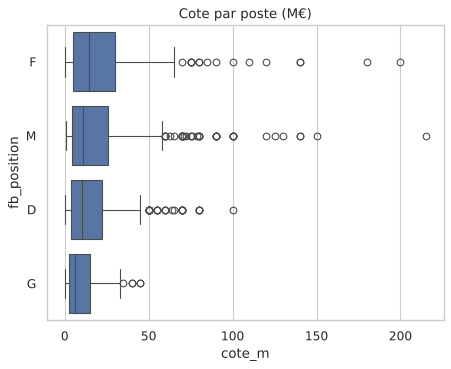

In [43]:
sns.boxplot(data=joueurs, x="cote_m", y="fb_position", order=ORDRE_POSTE)
plt.title("Cote par poste (M€)")
plt.show()

Même ordre que les médianes : attaquants au-dessus, gardiens en dessous. Le corps du marché reste sous 40 M€. Les points au-delà sont les stars, on les garde.

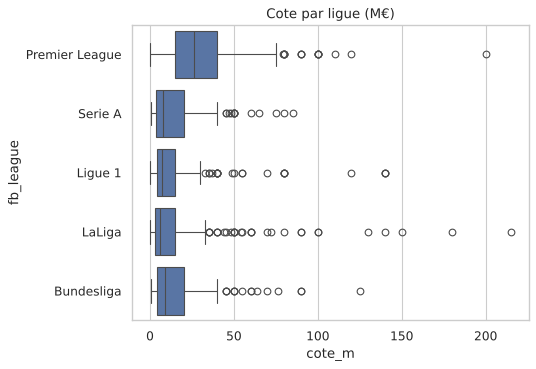

In [44]:
sns.boxplot(data=joueurs, x="cote_m", y="fb_league", order=ORDRE_LIGUE)
plt.title("Cote par ligue (M€)")
plt.show()

La boîte de la Premier League est nettement à droite des quatre autres, qui se tiennent entre elles (la Liga un peu plus bas). Les stars à plus de 100 M€, elles, ne sont pas qu'en Angleterre : on en voit surtout en Liga (jusqu'à 215 M€), mais aussi en Ligue 1 (PSG) et en Bundesliga, aucune en Serie A. La Premier League paie mieux le joueur moyen, pas seulement ses stars. On suppose que le championnat pèse sur le prix, pas seulement le niveau du joueur.

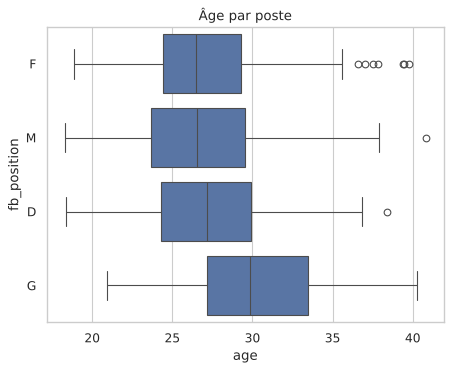

fb_position
D    27.2
F    26.5
G    29.8
M    26.5
Name: age, dtype: float64


In [45]:
sns.boxplot(data=joueurs, x="age", y="fb_position", order=ORDRE_POSTE)
plt.title("Âge par poste")
plt.show()
print(joueurs.groupby("fb_position")["age"].median().round(1))

Attaquants et milieux ont un âge médian de 26,5 ans, défenseurs 27,2, gardiens 29,8 : les gardiens jouent plus tard. L'âge n'est pas le même selon le poste, on le garde comme variable.

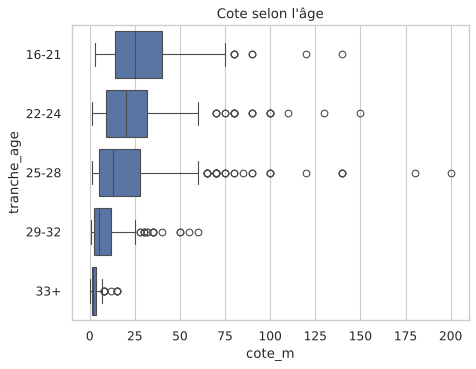

tranche_age
16-21    25.0
22-24    20.0
25-28    13.0
29-32     5.0
33+       2.0
Name: cote_m, dtype: float64


In [46]:
sns.boxplot(data=joueurs.dropna(subset=["tranche_age"]), x="cote_m", y="tranche_age")
plt.title("Cote selon l'âge")
plt.show()
print(joueurs.groupby("tranche_age", observed=False)["cote_m"].median())

La cote médiane baisse à chaque tranche d'âge : 25 M€ avant 22 ans, 20 M€ de 22 à 24, 13 M€ de 25 à 28, 5 M€ de 29 à 32, 2 M€ après 33. Un jeune qui joue déjà 900 minutes en Big 5 est payé pour ce qu'il deviendra.

Hypothèse : le marché paie aussi le temps de contrat qui reste, et les jeunes ont souvent des contrats plus longs. Transfermarkt ne le donne pas : on le testera plus bas avec SalarySport.

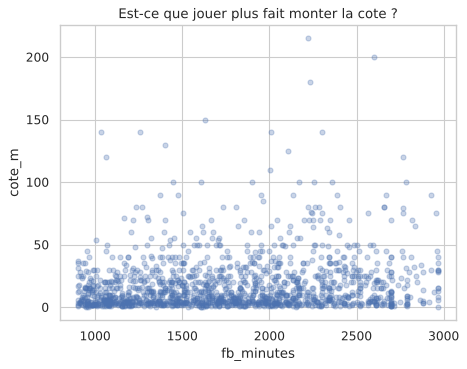

corrélation minutes / cote : 0.15


In [47]:
joueurs.plot.scatter(x="fb_minutes", y="cote_m", alpha=0.3)
plt.title("Est-ce que jouer plus fait monter la cote ?")
plt.show()
print("corrélation minutes / cote :", round(joueurs[["fb_minutes", "cote_m"]].corr().iloc[0, 1], 2))

Pas de lien clair entre minutes et cote. Le seuil de 900 sert à avoir des stats /90 stables, pas parce que plus on joue, plus on vaut.

In [48]:
# Stat par stat, poste par poste. On ne juge pas un gardien aux buts. En revanche un défenseur qui marque, ça reste un plus.

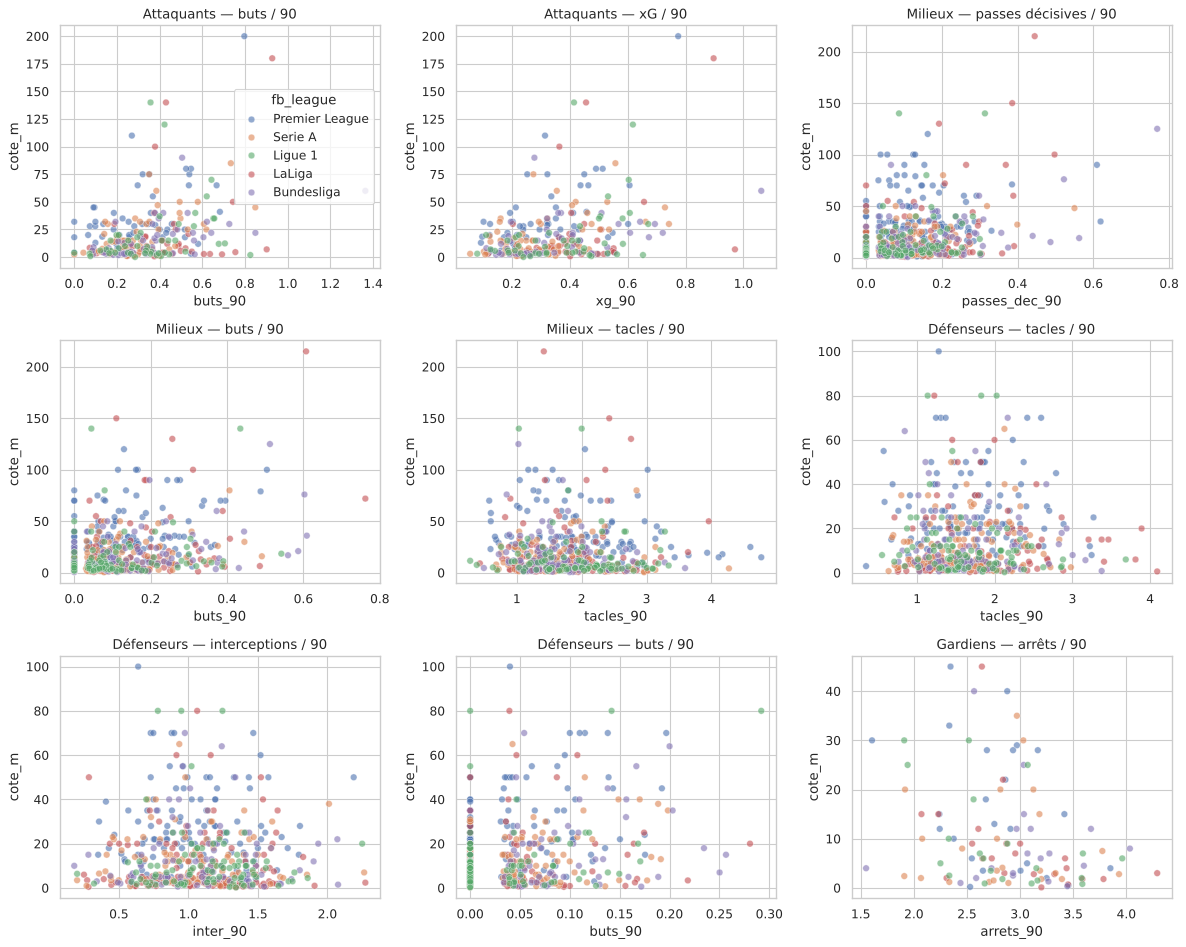

Attaquants — buts / 90 : corrélation de rang 0.31
Attaquants — xG / 90 : corrélation de rang 0.28
Milieux — passes décisives / 90 : corrélation de rang 0.3
Milieux — buts / 90 : corrélation de rang 0.33
Milieux — tacles / 90 : corrélation de rang -0.03
Défenseurs — tacles / 90 : corrélation de rang 0.02
Défenseurs — interceptions / 90 : corrélation de rang -0.02
Défenseurs — buts / 90 : corrélation de rang 0.22
Gardiens — arrêts / 90 : corrélation de rang -0.29


In [49]:
att = joueurs[joueurs["fb_position"] == "F"]
mil = joueurs[joueurs["fb_position"] == "M"]
defe = joueurs[joueurs["fb_position"] == "D"]
gb = joueurs[joueurs["fb_position"] == "G"]

graphes = [
    (att, "buts_90", "Attaquants — buts / 90"),
    (att, "xg_90", "Attaquants — xG / 90"),
    (mil, "passes_dec_90", "Milieux — passes décisives / 90"),
    (mil, "buts_90", "Milieux — buts / 90"),
    (mil, "tacles_90", "Milieux — tacles / 90"),
    (defe, "tacles_90", "Défenseurs — tacles / 90"),
    (defe, "inter_90", "Défenseurs — interceptions / 90"),
    (defe, "buts_90", "Défenseurs — buts / 90"),
    (gb, "arrets_90", "Gardiens — arrêts / 90"),
]
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
for ax, (df, col, titre) in zip(axes.flat, graphes):
    sns.scatterplot(data=df, x=col, y="cote_m", hue="fb_league", hue_order=ORDRE_LIGUE,
                    alpha=0.6, ax=ax, legend=(ax is axes.flat[0]))
    ax.set_title(titre)
plt.tight_layout()
plt.show()

for df, col, titre in graphes:
    print(titre, ": corrélation de rang", round(df[[col, "cote_m"]].corr(method="spearman").iloc[0, 1], 2))

Conclusion stat par stat : les stats offensives suivent un peu la cote (corrélation de rang autour de 0,3 pour les buts et passes décisives des attaquants et milieux, 0,22 pour les buts des défenseurs). Les stats défensives (tacles, interceptions) ne la suivent pas du tout. Les arrêts vont même à l'envers (−0,29) : un gardien qui fait beaucoup d'arrêts, c'est souvent un gardien d'une équipe qui subit.

Aucune stat, prise seule, ne fait le prix. Il faut combiner poste, championnat, âge et stats : c'est le rôle du modèle.

In [50]:
sans_tm = joueurs[joueurs["tm_id"].isna()]
avec_tm = joueurs[joueurs["tm_id"].notna()]
print("sans fiche TM", len(sans_tm), "/ avec", len(avec_tm))
print(sans_tm["fb_league"].value_counts())
print("médiane cote sans TM / avec TM :", sans_tm["cote_m"].median(), avec_tm["cote_m"].median())

sans fiche TM 262 / avec 1160
fb_league
LaLiga            64
Premier League    56
Bundesliga        55
Ligue 1           45
Serie A           42
Name: count, dtype: int64
médiane cote sans TM / avec TM : 11.1 10.0


Les 262 joueurs sans fiche Transfermarkt sont répartis sur les cinq ligues. Leur médiane est de 11,1 M€, contre 10 pour ceux qui ont matché : ce ne sont pas les joueurs les moins chers, plutôt des noms écrits autrement d'une source à l'autre. Ils sortiront toutefois du modèle 

## Modèle

In [51]:
modele = joueurs[joueurs["tm_id"].notna() & joueurs["age"].notna()].copy()
modele["cote_cible"] = modele["cote_cible"].clip(lower=100_000)
print("joueurs dans le modèle :", len(modele))
print(modele["fb_position"].value_counts())
print(modele["fb_league"].value_counts())

joueurs dans le modèle : 1160
fb_position
D    459
M    382
F    215
G    104
Name: count, dtype: int64
fb_league
Serie A           259
Premier League    255
LaLiga            235
Bundesliga        206
Ligue 1           205
Name: count, dtype: int64


In [52]:
# passage de la cote en log pour que les stars repérées plus haut ne tirent pas tout le modèle. En log, un écart de +0,7 veut dire « deux fois plus cher », quel que soit le niveau de prix.

In [53]:
modele["log_cote"] = np.log(modele["cote_cible"])
print(modele[["cote_cible", "log_cote"]].describe().round(2))

STATS = ["buts_90", "xg_90", "passes_dec_90", "xa_90", "tacles_90", "inter_90", "arrets_90"]
for c in STATS:
    modele[c] = modele[c].fillna(0)

         cote_cible  log_cote
count  1.160000e+03   1160.00
mean   1.832659e+07     16.09
std    2.244353e+07      1.20
min    1.000000e+05     11.51
25%    4.000000e+06     15.20
50%    1.000000e+07     16.12
75%    2.500000e+07     17.03
max    2.000000e+08     19.11


In [54]:
# on garde seulement les colonnes chiffrées, et une heatmap pour voir si deux stats racontent la même chose.

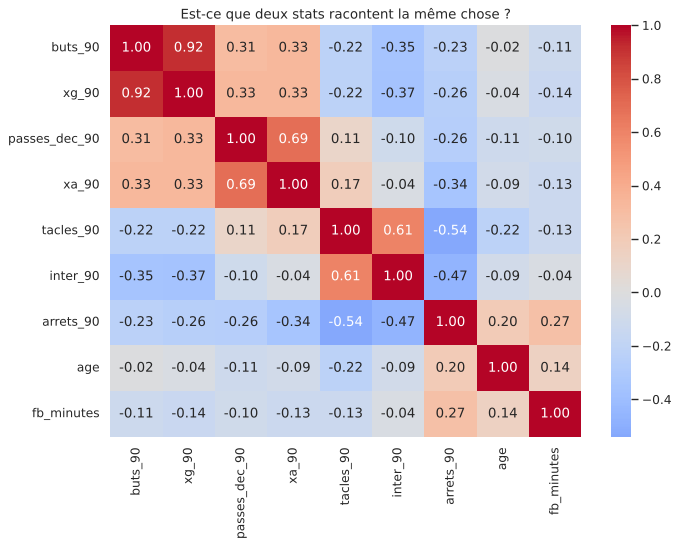

In [55]:
X_num = modele[STATS + ["age", "fb_minutes"]]
plt.figure(figsize=(9, 7))
sns.heatmap(X_num.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Est-ce que deux stats racontent la même chose ?")
plt.tight_layout()
plt.show()

Buts et xG montent ensemble (0,92) : celui qui se procure les occasions marque. Passes décisives et xA aussi (0,69), tacles et interceptions (0,61). On les garde quand même, parce que marquer et se créer une occasion ne sont pas la même chose, mais on lira leurs coefficients ensemble, pas un par un.
L'âge ne suit aucune stat (au plus 0,22) : il apporte quelque chose que le jeu ne dit pas.

In [56]:
# Poste et ligue en colonnes 0/1 car données textuelles. Le gardien et la Liga servent de référence : les coefficients se lisent par rapport à eux.

In [57]:
modele["poste_F"] = (modele["fb_position"] == "F").astype(int)
modele["poste_M"] = (modele["fb_position"] == "M").astype(int)
modele["poste_D"] = (modele["fb_position"] == "D").astype(int)
modele["ligue_PL"] = (modele["fb_league"] == "Premier League").astype(int)
modele["ligue_SA"] = (modele["fb_league"] == "Serie A").astype(int)
modele["ligue_L1"] = (modele["fb_league"] == "Ligue 1").astype(int)
modele["ligue_BL"] = (modele["fb_league"] == "Bundesliga").astype(int)

VARIABLES = STATS + ["age", "fb_minutes",
                     "poste_F", "poste_M", "poste_D",
                     "ligue_PL", "ligue_SA", "ligue_L1", "ligue_BL"]
X = modele[VARIABLES]
y = modele["log_cote"]
print(len(VARIABLES), "variables")

16 variables


In [58]:
# Découpage 80/20 

In [59]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("train", len(X_train), "/ test", len(X_test))

reg = LinearRegression()
reg.fit(X_train, y_train)
y_pred_test = reg.predict(X_test)
print("R² train :", round(r2_score(y_train, reg.predict(X_train)), 3))
print("R² test  :", round(r2_score(y_test, y_pred_test), 3))
print("erreur moyenne en € :", round(mean_absolute_error(np.exp(y_test), np.exp(y_pred_test)), -5))

train 928 / test 232
R² train : 0.66
R² test  : 0.618
erreur moyenne en € : 8800000.0


R² train 0,66, R² test 0,62 : le modèle explique environ 60 % de la cote en log sur des joueurs qu'il n'a pas vus, et il n'apprend pas par cœur (les deux chiffres sont proches).
L'erreur moyenne de 8,8 M€ est grossie par les stars : se tromper de 30 % sur un joueur à 100 M€, c'est 30 M€ d'écart.

       reelle_m  pred_m  ecart_m
count     232.0   232.0    232.0
mean       16.9    14.9      1.9
std        22.4    19.2     16.9
min         0.4     0.8    -73.1
25%         4.0     4.9     -3.8
50%        10.0     9.8     -0.4
75%        20.0    16.1      4.8
max       180.0   163.1    127.1


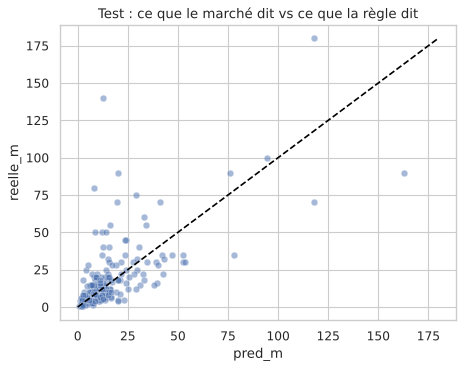

In [60]:
comparaison = pd.DataFrame({
    "reelle_m": np.exp(y_test) / 1_000_000,
    "pred_m": np.exp(y_pred_test) / 1_000_000,
})
comparaison["ecart_m"] = comparaison["reelle_m"] - comparaison["pred_m"]
print(comparaison.describe().round(1))

sns.scatterplot(data=comparaison, x="pred_m", y="reelle_m", alpha=0.5)
m_max = comparaison["reelle_m"].max()
plt.plot([0, m_max], [0, m_max], color="black", linestyle="--")
plt.title("Test : ce que le marché dit vs ce que la règle dit")
plt.show()

Sur les 232 joueurs de test, l'écart médian est quasi nul (−0,4 M€) : pour un joueur du milieu de tableau, la règle est proche du marché. En dessous de 30 M€, les points suivent à peu près la ligne. Au-dessus, ça s'écarte des deux côtés, de −73 M€ à +127 M€ : la règle décrit bien le milieu de tableau, moins bien les stars.

### Régression ou forêt ?

Un seul découpage peut tomber sur un tirage favorable. On compare donc aussi sur 5 blocs mélangés

In [61]:
rf = RandomForestRegressor(n_estimators=200, random_state=42, min_samples_leaf=5)
rf.fit(X_train, y_train)
print("forêt  R² train :", round(r2_score(y_train, rf.predict(X_train)), 3),
      "| R² test :", round(r2_score(y_test, rf.predict(X_test)), 3))

scores_reg = cross_val_score(LinearRegression(), X, y, cv=CV5, scoring="r2")
scores_rf = cross_val_score(
    RandomForestRegressor(n_estimators=200, random_state=42, min_samples_leaf=5),
    X, y, cv=CV5, scoring="r2")
print("droite, 5 blocs :", scores_reg.round(3), "moyenne", round(scores_reg.mean(), 3), "écart-type", round(scores_reg.std(), 3))
print("forêt,  5 blocs :", scores_rf.round(3), "moyenne", round(scores_rf.mean(), 3), "écart-type", round(scores_rf.std(), 3))

# pour mémoire : sans mélanger, chaque bloc est presque une ligue entière
print("droite, 5 blocs NON mélangés :", cross_val_score(LinearRegression(), X, y, cv=5, scoring="r2").round(3))

forêt  R² train : 0.832 | R² test : 0.559
droite, 5 blocs : [0.618 0.635 0.677 0.652 0.635] moyenne 0.643 écart-type 0.02
forêt,  5 blocs : [0.569 0.603 0.608 0.628 0.623] moyenne 0.606 écart-type 0.021
droite, 5 blocs NON mélangés : [ 0.044  0.235 -0.071  0.243  0.512]


Sur 5 blocs mélangés, la droite fait 0,64 en moyenne et la forêt 0,61. La droite est devant sur les cinq blocs, et les deux sont stables (écart-type 0,02).
La forêt fait 0,83 sur les joueurs qu'elle a vus et 0,56 dehors : elle apprend par cœur. On garde la régression linéaire : elle généralise mieux.

## Analyse du modèle

Le R² dit combien le modèle explique, pas **ce qu'il a appris**. Trois vérifications :
1. lire les coefficients, en pourcentage de cote ;
2. regarder les erreurs (résidus) : sont-elles au hasard, ou le modèle se trompe-t-il toujours au même endroit ?
3. demander à la forêt quelles variables elle utilise, pour voir si elle raconte la même chose que la droite.

     variable   coef   pas  effet_pct
    arrets_90 -0.684   1.0    -49.546
          age -0.186   1.0    -16.975
     ligue_L1 -0.140   1.0    -13.067
    tacles_90 -0.103   1.0     -9.781
     ligue_BL -0.077   1.0     -7.452
passes_dec_90  1.126   0.1     11.918
        xg_90  1.321   0.1     14.122
     ligue_SA  0.143   1.0     15.331
      buts_90  1.887   0.1     20.769
     inter_90  0.227   1.0     25.475
   fb_minutes  0.000 500.0     25.668
        xa_90  2.632   0.1     30.109
     ligue_PL  0.961   1.0    161.419


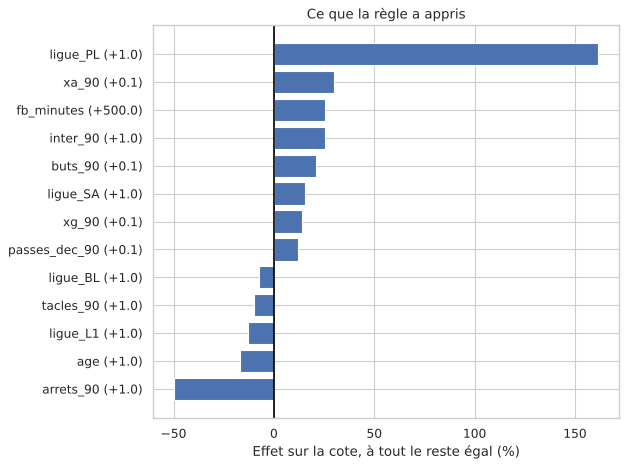

In [62]:
reg_full = LinearRegression().fit(X, y)   # sur tous les joueurs, pour lire les coefficients

# Une stat /90 de +1, c'est énorme (1 but de plus par match). On lit chaque coefficient pour un pas réaliste.
pas = {"buts_90": 0.1, "xg_90": 0.1, "passes_dec_90": 0.1, "xa_90": 0.1,
       "tacles_90": 1, "inter_90": 1, "arrets_90": 1, "age": 1, "fb_minutes": 500}
lecture = pd.DataFrame({"variable": VARIABLES, "coef": reg_full.coef_})
lecture["pas"] = lecture["variable"].map(pas).fillna(1)
lecture["effet_pct"] = (np.exp(lecture["coef"] * lecture["pas"]) - 1) * 100
lecture = lecture.sort_values("effet_pct")

lecture = lecture[~lecture["variable"].str.startswith("poste_")]
print(lecture.round(3).to_string(index=False))

plt.figure(figsize=(8, 6))
plt.barh(lecture["variable"] + " (+" + lecture["pas"].astype(str) + ")", lecture["effet_pct"])
plt.axvline(0, color="black")
plt.xlabel("Effet sur la cote, à tout le reste égal (%)")
plt.title("Ce que la règle a appris")
plt.tight_layout()
plt.show()

Lecture, à tout le reste égal, par rapport à un joueur de Liga :
- Ligue : la Premier League multiplie la cote par 2,6 (+161 %). Serie A +15 %, Bundesliga −7 %, Ligue 1 −13 %.
- Âge : −17 % par année. C'est le plus gros effet continu.
- Stats offensives : +0,1 xA/90 = +30 %, +0,1 but/90 = +21 %, +0,1 xG/90 = +14 %, +0,1 passe décisive/90 = +12 %. Buts et xG vont ensemble (0,92) : on lit leur effet cumulé.
- Stats défensives : +1 interception/90 = +25 %, mais +1 tacle/90 = −10 % : un joueur qui tacle beaucoup est souvent dans une équipe qui n'a pas le ballon.
- Arrêts : −50 % par arrêt/90 en plus, même lecture que plus haut.
- Minutes : +500 minutes = +26 %. Seules, les minutes ne suivaient pas la cote ; à âge et ligue égaux, être titulaire compte.

Les colonnes poste ne se lisent pas seules. Par exemple, les arrets n'existent que pour les gardiens, donc « gardien » dans la règle veut dire « gardien avec ses arrêts ». On choisit de comparer plutôt joueur type pour chaque poste : stats médianes de son poste, 26 ans, 1 800 minutes, même championnat.

In [63]:
# joueur type

In [64]:
types = []
for p in ORDRE_POSTE:
    profil = modele.loc[modele["fb_position"] == p, VARIABLES].median()
    profil[["ligue_PL", "ligue_SA", "ligue_L1", "ligue_BL"]] = 0
    profil["age"] = 26
    profil["fb_minutes"] = 1800
    types.append(profil)
types = pd.DataFrame(types, index=ORDRE_POSTE)
print("cote prédite d'un joueur type (M€), Liga, 26 ans :")
print(pd.Series(np.exp(reg_full.predict(types[VARIABLES])) / 1e6, index=ORDRE_POSTE).round(1).to_string())
print("le même en Premier League : x", round(np.exp(reg_full.coef_[VARIABLES.index("ligue_PL")]), 2))

cote prédite d'un joueur type (M€), Liga, 26 ans :
F    11.9
M     9.3
D     8.3
G     8.1
le même en Premier League : x 2.61


Joueur type à 26 ans en Liga : attaquant 11,9 M€, milieu 9,3, défenseur 8,3, gardien 8,1. Même ordre que les médianes du début. Le même joueur en Premier League vaut 2,6 fois plus.

In [65]:
# nuage points résidu marché règle

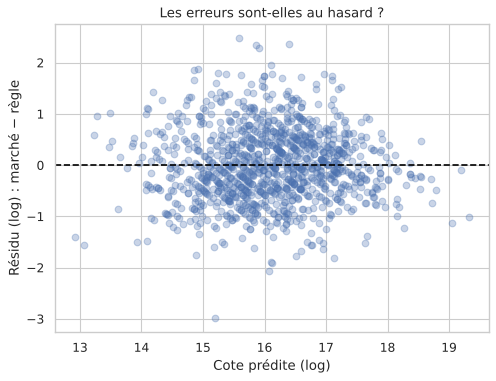

           median   std
très bas    -0.15  0.77
bas         -0.11  0.70
milieu       0.03  0.77
haut         0.10  0.69
très haut   -0.09  0.59


In [66]:
pred_full = reg_full.predict(X)
residus = y - pred_full
plt.figure(figsize=(7, 5))
plt.scatter(pred_full, residus, alpha=0.3)
plt.axhline(0, color="black", linestyle="--")
plt.xlabel("Cote prédite (log)")
plt.ylabel("Résidu (log) : marché − règle")
plt.title("Les erreurs sont-elles au hasard ?")
plt.show()

tranches_pred = pd.qcut(pred_full, 5, labels=["très bas", "bas", "milieu", "haut", "très haut"])
print(pd.Series(residus.values).groupby(tranches_pred, observed=False).agg(["median", "std"]).round(2))

Les erreurs ont l'air au hasard : quel que soit le niveau de prix prédit, l'écart médian reste entre −0,15 et +0,10, et la dispersion est à peu près la même (0,6 à 0,8). La règle ne surestime pas systématiquement les petits ni ne sous-estime systématiquement les gros. En log, elle se trompe autant pour un joueur à 2 M€ que pour une star ; c'est donc en euros que l'erreur sur les stars paraît énorme.

In [67]:
# importance critère par la forêt

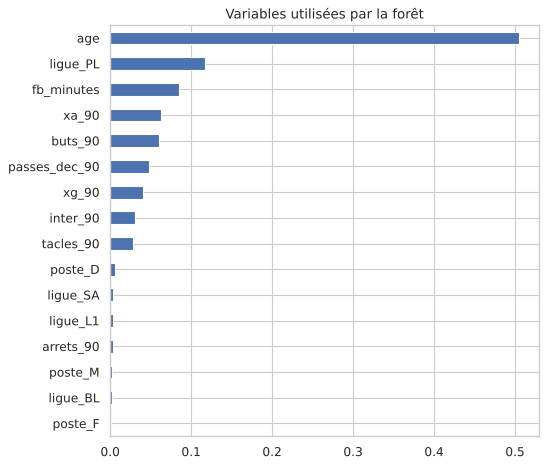

age              0.505
ligue_PL         0.117
fb_minutes       0.085
xa_90            0.063
buts_90          0.061
passes_dec_90    0.048
dtype: float64


In [68]:
rf_full = RandomForestRegressor(n_estimators=200, random_state=42, min_samples_leaf=5).fit(X, y)
importance = pd.Series(rf_full.feature_importances_, index=VARIABLES).sort_values()
importance.plot.barh(figsize=(7, 6))
plt.title("Variables utilisées par la forêt")
plt.tight_layout()
plt.show()
print(importance.sort_values(ascending=False).round(3).head(6))

L'âge est donc le critère le plus important suivi du championnat et des minutes. Les stats des postes plus défensifs sont moins essentielles.

## Écart entre le marché et la règle

L'écart se calcule en log. En log, les deux côtés sont symétriques.

In [69]:
# marché au dessus de la règle

In [70]:
modele["cote_predite"] = np.exp(pred_full)
modele["ecart_log"] = modele["log_cote"] - pred_full
modele["multiplicateur"] = np.exp(modele["ecart_log"])
colonnes = ["fb_name", "fb_league", "fb_position", "tm_club_name", "cote_cible", "cote_predite", "ecart_log", "multiplicateur"]
print("Marché AU-DESSUS de la règle")
print(modele.sort_values("ecart_log", ascending=False)[colonnes].head(12).round(2).to_string())

Marché AU-DESSUS de la règle
                    fb_name   fb_league fb_position         tm_club_name   cote_cible  cote_predite  ecart_log  multiplicateur
921         Dayot Upamecano  Bundesliga           D        Bayern Munich   70000000.0    5841269.26       2.48           11.98
1176                Vitinha     Ligue 1           M  Paris Saint-Germain  140000000.0   13181806.79       2.36           10.62
1183          Willian Pacho     Ligue 1           D  Paris Saint-Germain   80000000.0    7694685.58       2.34           10.40
1181          Achraf Hakimi     Ligue 1           D  Paris Saint-Germain   80000000.0    8084383.54       2.29            9.90
334     Aurélien Tchouaméni      LaLiga           M          Real Madrid   70000000.0    9834436.23       1.96            7.12
370        Robin Le Normand      LaLiga           D   Atlético de Madrid   20000000.0    3036893.97       1.88            6.59
1186        Lucas Hernandez     Ligue 1           D  Paris Saint-Germain   1800000

Les joueurs que le marché paie le plus au-dessus de la règle jouent presque tous dans un grand club : 11 sur 12 (PSG, Bayern, Real, Barça, Atlético), le seul autre est Zakaria à Monaco. Upamecano vaut 12 fois ce que ses stats annoncent.
Beaucoup sont des défenseurs.

In [71]:
# marché en dessous de la règle

In [72]:
print("Marché EN DESSOUS de la règle")
print(modele.sort_values("ecart_log")[colonnes].head(12).round(2).to_string())

Marché EN DESSOUS de la règle
                   fb_name       fb_league fb_position                    tm_club_name  cote_cible  cote_predite  ecart_log  multiplicateur
226            Karl Darlow  Premier League           G                    Leeds United    200000.0    3943295.99      -2.98            0.05
897        Lorenzo Montipo         Serie A           G                   Hellas Verona   1200000.0    9535657.87      -2.07            0.13
1163        Julian Niehues      Bundesliga           M  1. Fußballclub Heidenheim 1846   1500000.0   10091813.79      -1.91            0.15
826          Edoardo Corvi         Serie A           G               Parma Calcio 1913   1500000.0    9909950.11      -1.89            0.15
867    Filippo Terracciano         Serie A           D                    US Cremonese   4500000.0   27466563.56      -1.81            0.16
881           Danilo Veiga         Serie A           D                        US Lecce   2500000.0   14861463.71      -1.78       

En dessous de la règle : surtout des gardiens et des joueurs de petits clubs. La règle leur donne la valeur d'un joueur moyen de leur ligue ; le marché, lui, sait qu'ils sont dans un club du bas de tableau.

In [73]:
# écart marché/règle

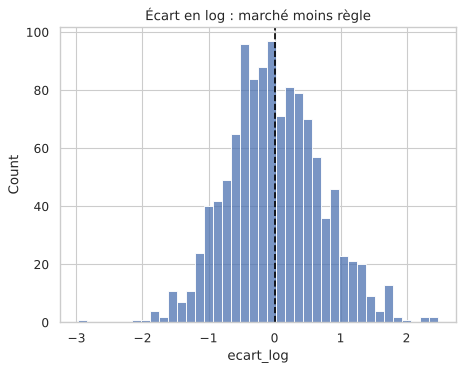

count    1160.00
mean       -0.00
std         0.71
min        -2.98
25%        -0.47
50%        -0.04
75%         0.46
max         2.48
Name: ecart_log, dtype: float64
part entre -0,7 et +0,7 (moins de 2 fois d'écart) : 0.69


In [74]:
sns.histplot(modele["ecart_log"], bins=40)
plt.axvline(0, color="black", linestyle="--")
plt.title("Écart en log : marché moins règle")
plt.show()
print(modele["ecart_log"].describe().round(2))
print("part entre -0,7 et +0,7 (moins de 2 fois d'écart) :", round(modele["ecart_log"].between(-0.7, 0.7).mean(), 2))

Le gros du tas est autour de 0, la règle. Écart-type 0,71 ; 69 % des joueurs sont à moins de deux fois la règle (entre −0,7 et +0,7). Les extrêmes vont de −3 à +2,5.
En log, l'histogramme est à peu près symétrique : le marché s'écarte des deux côtés, il brade aussi.

In [75]:
# écarts par postes et par championnats

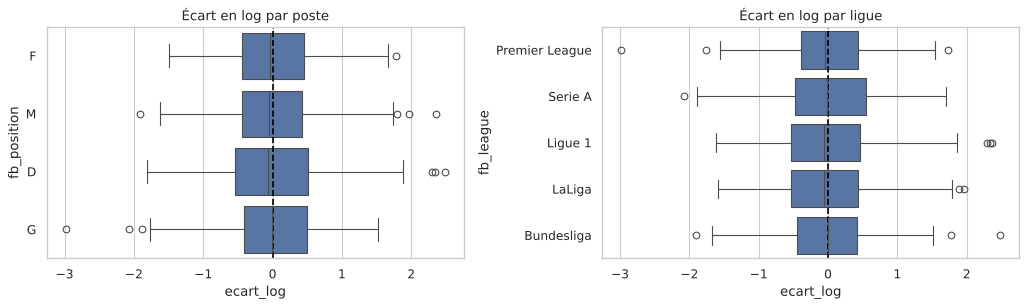

In [76]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=modele, x="ecart_log", y="fb_position", order=ORDRE_POSTE, ax=axes[0])
axes[0].axvline(0, color="black", linestyle="--")
axes[0].set_title("Écart en log par poste")
sns.boxplot(data=modele, x="ecart_log", y="fb_league", order=ORDRE_LIGUE, ax=axes[1])
axes[1].axvline(0, color="black", linestyle="--")
axes[1].set_title("Écart en log par ligue")
plt.tight_layout()
plt.show()

Les boîtes restent autour de 0, par poste comme par ligue. On suppose que le reste vient du club, du contrat, ou d'un nom que les stats ne voient pas, c'est ce qu'on va tester.

## Test « grand club »

On ajoute une seule colonne, grand club oui/non, et on compare sur les mêmes 5 blocs mélangés.

In [77]:
modele["grand_club"] = modele["tm_club_name"].map(est_grand_club)
print(modele["grand_club"].value_counts())
print(sorted(modele.loc[modele["grand_club"] == 1, "tm_club_name"].unique()))

r2_sans_club = cross_val_score(LinearRegression(), X, y, cv=CV5).mean()
r2_avec_club = cross_val_score(LinearRegression(), modele[VARIABLES + ["grand_club"]], y, cv=CV5).mean()
print("R² 5 blocs sans le maillot :", round(r2_sans_club, 3))
print("R² 5 blocs avec le maillot :", round(r2_avec_club, 3))

reg_club = LinearRegression().fit(modele[VARIABLES + ["grand_club"]], y)
coef_club = reg_club.coef_[-1]
print("poids grand_club :", round(coef_club, 3), "→ multiplicateur", round(np.exp(coef_club), 2))
print("écart médian à la règle, petit club / grand club :")
print(modele.groupby("grand_club")["ecart_log"].median().round(2))

grand_club
0    974
1    186
Name: count, dtype: int64
['AC Milan', 'Arsenal FC', 'Atlético de Madrid', 'Bayern Munich', 'Borussia Dortmund', 'Chelsea FC', 'FC Barcelona', 'Inter Milan', 'Juventus FC', 'Liverpool FC', 'Manchester City', 'Manchester United', 'Paris Saint-Germain', 'Real Madrid']
R² 5 blocs sans le maillot : 0.643
R² 5 blocs avec le maillot : 0.728
poids grand_club : 1.033 → multiplicateur 2.81
écart médian à la règle, petit club / grand club :
grand_club
0   -0.15
1    0.68
Name: ecart_log, dtype: float64


186 joueurs jouent dans un des 14 grands clubs. En ajoutant seulement cette colonne, le R² sur 5 blocs passe de 0,64 à 0,73. À stats, âge, poste et ligue égaux, un joueur de grand club vaut 2,8 fois plus. L'écart médian à la règle est de +0,68 pour eux, contre −0,15 pour les autres. Le maillot pèse donc vraiment.

On ne l'intègre pas à la règle affichée. Si on le faisait, un titulaire du Real ou du PSG ne sortirait plus comme un écart : le club aurait déjà été absorbé dans le prix. On préfère laisser cet écart visible, et citer le 0,73 comme vérification, pas comme modèle final.

## Salaire et fin de contrat (SalarySport, web scraping)

SalarySport n'a pas d'API : on lit directement le HTML des cinq pages « contrats qui expirent en 2026 … 2030 ».

**Étapes du scraping**
1. `requests` télécharge la page (session avec 5 nouvelles tentatives en cas d'erreur 429/500, une pause de 2 s entre deux pages).
2. On force l'encodage UTF-8 : sans ça, « Bayern München » sortait en « MÃ¼nchen » et les noms à accent ne se recoupaient plus.
3. **BeautifulSoup** lit le HTML : on cherche le `<table>` dont les en-têtes `<th>` contiennent PLAYER, YEARLY, EXPIRES, CLUB, LEAGUE, puis on lit chaque ligne `<tr>` cellule par cellule (`<td>`).
4. On nettoie : `£414,000` → 414000, `JUN 2029` → 30/06/2029, et on coupe le rang et la ligue parfois collés au nom.
5. Chaque étape est écrite dans un **log** (heure, niveau, message), affiché ici et gardé dans `scraping_salarysport.log`.

Avant de scraper, le code tente de lire `robots.txt`. Lors du relevé du 07/10/2026, cette lecture a échoué (certificat SSL) : c'est noté dans le log, et la charge reste limitée à cinq pages avec une pause entre chacune.

`SCRAPER = False` (par défaut) relit le CSV déjà extrait le 07/10/2026 et réaffiche le log du scraping. `SCRAPER = True` relance le scraping On ne réécrit le CSV que si les cinq pages ont été lues.

In [78]:
import logging
import sys
from urllib.robotparser import RobotFileParser
from bs4 import BeautifulSoup
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

chemin_sal = DOSSIER / "salarysport_top5_salaires_contrats.csv"
chemin_log = DOSSIER / "scraping_salarysport.log"

# Logger : une ligne = heure | niveau | message, à l'écran et dans un fichier
log = logging.getLogger("salarysport")
log.setLevel(logging.INFO)
log.handlers.clear()
log.propagate = False
format_log = logging.Formatter("%(asctime)s | %(levelname)-7s | %(message)s", datefmt="%Y-%m-%d %H:%M:%S")
ecran = logging.StreamHandler(sys.stdout)
ecran.setFormatter(format_log)
log.addHandler(ecran)

# Session HTTP : en-têtes de navigateur et nouvelles tentatives automatiques
session = requests.Session()
session.mount("https://", HTTPAdapter(max_retries=Retry(
    total=5, backoff_factor=1, status_forcelist=[429, 500, 502, 503, 504], allowed_methods=["GET"])))
session.headers.update({
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/154.0 Safari/537.36",
    "Accept-Language": "en-GB,en;q=0.9,fr;q=0.8",
})

ANNEES_PAGES = [2026, 2027, 2028, 2029, 2030]
LIGUES_SAL = ["Premier League", "La Liga", "Serie A", "Bundesliga", "Ligue 1"]
COLONNES_UTILES = {"PLAYER", "YEARLY", "EXPIRES", "CLUB", "LEAGUE"}

Fonctions de nettoyage du tableau scrapé.

In [79]:
MOIS = {"JAN": 1, "FEB": 2, "MAR": 3, "APR": 4, "MAY": 5, "JUN": 6,
        "JUL": 7, "AUG": 8, "SEP": 9, "OCT": 10, "NOV": 11, "DEC": 12}

def salaire_en_nombre(valeur):
    # '£414,000' -> 414000.0
    if pd.isna(valeur):
        return None
    texte = re.sub(r"[^\d.\-]", "", str(valeur))
    return float(texte) if texte else None

def date_fin(valeur):
    # 'JUN 2029' -> 2029-06-30 (dernier jour du mois)
    if pd.isna(valeur):
        return pd.NaT
    trouve = re.search(r"(JAN|FEB|MAR|APR|MAY|JUN|JUL|AUG|SEP|OCT|NOV|DEC)\s+(\d{4})", str(valeur).upper())
    if not trouve:
        return pd.NaT
    m_ = MOIS[trouve.group(1)]
    a = int(trouve.group(2))
    return pd.Timestamp(year=a, month=m_, day=calendar.monthrange(a, m_)[1])

def nom_seul(ligne):
    # '01 Kylian Mbappé La Liga · 26 · Winger' -> 'Kylian Mbappé'
    nom = re.sub(r"^\d+\s*", "", str(ligne["PLAYER"])).strip()
    ligue = str(ligne["LEAGUE"]).strip()
    if ligue and ligue.lower() != "nan" and ligue in nom:
        nom = nom.split(ligue)[0].strip()
    return nom

Lecture d'une page avec BeautifulSoup.

In [80]:
def lire_page(annee):
    url = f"https://salarysport.com/football/contracts-expiring-{annee}/"
    log.info("GET %s", url)
    reponse = session.get(url, timeout=30)
    reponse.encoding = "utf-8"
    log.info("HTTP %s | %s octets reçus", reponse.status_code, f"{len(reponse.content):,}".replace(",", " "))
    reponse.raise_for_status()

    soup = BeautifulSoup(reponse.text, "html.parser")
    tableaux = soup.find_all("table")
    log.info("%d tableau(x) <table> dans la page", len(tableaux))

    for table in tableaux:
        entetes = [th.get_text(" ", strip=True).upper() for th in table.find_all("th")]
        if not entetes and table.find("tr"):        # en-têtes écrits en <td> dans la 1re ligne
            entetes = [td.get_text(" ", strip=True).upper() for td in table.find("tr").find_all("td")]
        if not COLONNES_UTILES.issubset(entetes):
            continue
        lignes = []
        for tr in table.find_all("tr"):
            cellules = [td.get_text(" ", strip=True) for td in tr.find_all("td")]
            if len(cellules) == len(entetes):      # on saute l'en-tête et les lignes incomplètes
                lignes.append(cellules)
        page = pd.DataFrame(lignes, columns=entetes)
        log.info("tableau joueurs trouvé : %d lignes, colonnes %s", len(page), entetes)
        return page

    log.warning("aucun tableau avec %s sur %s", sorted(COLONNES_UTILES), url)
    return None

Boucle sur les cinq pages, nettoyage, export.

In [81]:
if SCRAPER:
    fichier = logging.FileHandler(chemin_log, mode="w", encoding="utf-8")
    fichier.setFormatter(format_log)
    log.addHandler(fichier)
    log.info("=== DÉBUT DU SCRAPING SALARYSPORT ===")

    robots = RobotFileParser("https://salarysport.com/robots.txt")
    try:
        robots.read()
        autorise = robots.can_fetch("*", "https://salarysport.com/football/contracts-expiring-2027/")
        log.info("robots.txt : lecture des pages contrats autorisée = %s", autorise)
    except Exception as e:
        log.warning("robots.txt illisible (%s)", e)

    pages = []
    for annee in ANNEES_PAGES:
        try:
            page = lire_page(annee)
            if page is not None:
                pages.append(page)
        except Exception as e:
            log.error("page %s non lue : %s", annee, e)
        time.sleep(2)   # pause entre deux pages, pour ne pas charger le site

    if len(pages) == len(ANNEES_PAGES):
        brut = pd.concat(pages, ignore_index=True)
        log.info("%d lignes au total, toutes ligues", len(brut))
        brut = brut[brut["LEAGUE"].isin(LIGUES_SAL)].copy()
        log.info("%d lignes après filtre Big 5", len(brut))
        brut["PLAYER"] = brut.apply(nom_seul, axis=1)
        brut["YEARLY_SALARY_GBP"] = brut["YEARLY"].apply(salaire_en_nombre)
        brut["CONTRACT_END_DATE"] = brut["EXPIRES"].apply(date_fin)
        brut["CONTRACT_YEARS_REMAINING"] = ((brut["CONTRACT_END_DATE"] - DATE_REF).dt.days / 365.25).round(2)
        log.info("salaires illisibles : %d | dates illisibles : %d",
                 brut["YEARLY_SALARY_GBP"].isna().sum(), brut["CONTRACT_END_DATE"].isna().sum())
        avant = len(brut)
        brut = brut.drop_duplicates(["PLAYER", "CLUB"])
        log.info("doublons joueur + club retirés : %d", avant - len(brut))
        brut.to_csv(chemin_sal, index=False, encoding="utf-8-sig")
        log.info("CSV écrit : %s (%d joueurs)", chemin_sal.name, len(brut))
    else:
        log.error("%d page(s) sur %d lues : on garde le CSV déjà extrait", len(pages), len(ANNEES_PAGES))
    log.info("=== FIN DU SCRAPING ===")
    log.removeHandler(fichier)
    fichier.close()
else:
    print("SCRAPER = False : on relit", chemin_sal.name)
    if chemin_log.exists():
        print("Log du dernier scraping :")
        print(chemin_log.read_text(encoding="utf-8"))
    else:
        print("Pas encore de log : passer SCRAPER = True une fois pour en créer un.")

SCRAPER = False : on relit salarysport_top5_salaires_contrats.csv
Log du dernier scraping :
2026-10-07 19:11:44 | INFO    | === DÉBUT DU SCRAPING SALARYSPORT ===
2026-10-07 19:11:45 | WARNING | robots.txt illisible (<urlopen error [SSL: CERTIFICATE_VERIFY_FAILED] certificate verify failed: unable to get local issuer certificate (_ssl.c:1082)>)
2026-10-07 19:11:45 | INFO    | GET https://salarysport.com/football/contracts-expiring-2026/
2026-10-07 19:11:45 | INFO    | HTTP 200 | 1 691 175 octets reçus
2026-10-07 19:11:45 | INFO    | 1 tableau(x) <table> dans la page
2026-10-07 19:11:45 | INFO    | tableau joueurs trouvé : 1748 lignes, colonnes ['PLAYER', 'WEEKLY', 'YEARLY', 'EXPIRES', 'CLUB', 'LEAGUE', 'AGE', 'POSITION']
2026-10-07 19:11:47 | INFO    | GET https://salarysport.com/football/contracts-expiring-2027/
2026-10-07 19:11:47 | INFO    | HTTP 200 | 1 732 007 octets reçus
2026-10-07 19:11:48 | INFO    | 1 tableau(x) <table> dans la page
2026-10-07 19:11:48 | INFO    | tableau joue

In [82]:
# jointure sur nom et championnat

In [83]:
def reparer(texte):
    texte = str(texte)
    for codage in ("cp1252", "latin-1"):
        try:
            return texte.encode(codage).decode("utf-8")
        except (UnicodeEncodeError, UnicodeDecodeError):
            pass
    # « à » s'écrit Ã + espace insécable, l'espace a été perdu au scraping
    return re.sub(r"Ã( |$)", r"à\1", texte)

sal = pd.read_csv(chemin_sal, encoding="utf-8-sig")
avant = sal["PLAYER"].str.contains("Ã|Å|Ä").sum()
for col in ["PLAYER", "CLUB"]:
    sal[col] = sal[col].map(reparer)
print("noms abîmés avant / après réparation :", avant, "/", sal["PLAYER"].str.contains("Ã|Å|Ä").sum())

sal["nom_norm"] = sal["PLAYER"].map(norm_nom)
sal["fb_league"] = sal["LEAGUE"].replace({"La Liga": "LaLiga"})
sal["salaire_an_gbp"] = pd.to_numeric(sal["YEARLY_SALARY_GBP"], errors="coerce")
sal["fin_contrat"] = pd.to_datetime(sal["CONTRACT_END_DATE"], errors="coerce")
sal["annees_contrat"] = ((sal["fin_contrat"] - DATE_REF).dt.days / 365.25).round(2)
print(sal.shape)
print(sal["fb_league"].value_counts())
print("salaires vides :", int(sal["salaire_an_gbp"].isna().sum()), "| années vides :", int(sal["annees_contrat"].isna().sum()))
print(sal["annees_contrat"].describe().round(2))

# homonymes : même nom dans la même ligue → on ne sait pas lequel est le bon, on les enlève
homonymes = sal.duplicated(["nom_norm", "fb_league"], keep=False)
print("homonymes nom + ligue retirés :", int(homonymes.sum()))
sal = sal[~homonymes]
print(sal[["PLAYER", "CLUB", "salaire_an_gbp", "annees_contrat"]].head())

noms abîmés avant / après réparation : 0 / 0
(1980, 16)
fb_league
Premier League    529
Serie A           451
Bundesliga        428
LaLiga            309
Ligue 1           263
Name: count, dtype: int64
salaires vides : 0 | années vides : 0
count    1980.00
mean        1.97
std         1.29
min         0.00
25%         1.00
50%         2.00
75%         3.00
max         4.00
Name: annees_contrat, dtype: float64
homonymes nom + ligue retirés : 0
             PLAYER               CLUB  salaire_an_gbp  annees_contrat
0       David Alaba        Real Madrid      19396000.0             0.0
1      Manuel Neuer  FC Bayern München      15496000.0             0.0
2     Leon Goretzka  FC Bayern München      14664000.0             0.0
3      Jadon Sancho        Aston Villa      14300000.0             0.0
4  Thibaut Courtois        Real Madrid      13312000.0             0.0


Jointure sur nom + ligue, comme pour Transfermarkt. Un contrat qui finit après 2030 n'est pas sur ces pages.

In [84]:
# réparation accents
# jointure des salaires avec les joueurs, sur nom + ligue
cols_sal = ["nom_norm", "fb_league", "salaire_an_gbp", "annees_contrat", "fin_contrat"]
base = joueurs.merge(sal[cols_sal], on=["nom_norm", "fb_league"], how="left")
print("tous les joueurs  : avec salaire", int(base["salaire_an_gbp"].notna().sum()), "/", len(base))

ok = modele.merge(sal[cols_sal], on=["nom_norm", "fb_league"], how="inner")
ok["salaire_m"] = ok["salaire_an_gbp"] / 1_000_000
ok["log_salaire"] = np.log(ok["salaire_an_gbp"])
print("joueurs du modèle : avec salaire", len(ok), "/", len(modele))
print(ok["fb_league"].value_counts())

tous les joueurs  : avec salaire 843 / 1422
joueurs du modèle : avec salaire 719 / 1160
fb_league
Serie A           185
Premier League    177
Bundesliga        145
LaLiga            116
Ligue 1            96
Name: count, dtype: int64


Le CSV fourni a déjà été réparé : 0 nom abîmé ici (sur le premier relevé, la réparation avait remis 396 noms sur 397).
843 joueurs sur 1 422 retrouvent un salaire, dont 719 sur les 1 160 du modèle. Les autres ne sont pas forcément des ratés de jointure : un contrat qui finit après 2030 n'est pas sur ces pages, et SalarySport ne liste pas tout le monde. Les cinq ligues sont représentées, la Ligue 1 un peu moins (96 joueurs).

In [85]:
print("médiane salaire M£ par poste")
print(ok.groupby("fb_position")["salaire_m"].median().reindex(ORDRE_POSTE).round(2))
print("médiane salaire M£ par ligue")
print(ok.groupby("fb_league")["salaire_m"].median().reindex(ORDRE_LIGUE).round(2))
print(ok[["annees_contrat", "log_cote", "age", "log_salaire"]].corr().round(2))

médiane salaire M£ par poste
fb_position
F    2.24
M    2.29
D    2.16
G    1.56
Name: salaire_m, dtype: float64
médiane salaire M£ par ligue
fb_league
Premier League    4.06
Serie A           1.92
Ligue 1           1.20
LaLiga            1.25
Bundesliga        1.66
Name: salaire_m, dtype: float64
                annees_contrat  log_cote   age  log_salaire
annees_contrat            1.00      0.53 -0.57         0.15
log_cote                  0.53      1.00 -0.64         0.51
age                      -0.57     -0.64  1.00         0.11
log_salaire               0.15      0.51  0.11         1.00


Le poste trie peu le salaire chez les joueurs de champ ; seuls les gardiens sont plus bas. Le championnat, si. Même lecture que pour les cotes : le championnat paie, le poste beaucoup moins.

In [86]:
# Cotes et ages selon le contrat restant

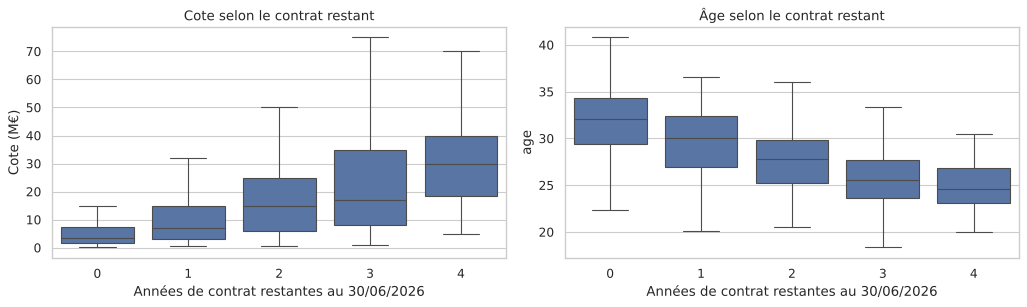

       joueurs  cote_mediane  age_median
duree                                   
0           84           3.5        32.1
1          150           7.0        30.1
2          172          15.0        27.8
3          195          17.0        25.5
4          118          30.0        24.5


In [87]:
ok["duree"] = ok["annees_contrat"].round().astype(int)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=ok, x="duree", y="cote_m", showfliers=False, ax=axes[0])
axes[0].set_xlabel("Années de contrat restantes au 30/06/2026")
axes[0].set_ylabel("Cote (M€)")
axes[0].set_title("Cote selon le contrat restant")
sns.boxplot(data=ok, x="duree", y="age", showfliers=False, ax=axes[1])
axes[1].set_xlabel("Années de contrat restantes au 30/06/2026")
axes[1].set_title("Âge selon le contrat restant")
plt.tight_layout()
plt.show()
print(ok.groupby("duree").agg(joueurs=("cote_m", "size"), cote_mediane=("cote_m", "median"), age_median=("age", "median")).round(1))

La cote médiane monte nettement avec le contrat restant.
Mais le graphique de droite montre que l'âge baisse en même temps. On ne peut pas conclure avec seulement ce graphique.

In [88]:
# séparation contrat et âge avec l'écart à la règle qui était djà fonction de l'âge, des stats, du poste et du championnat.

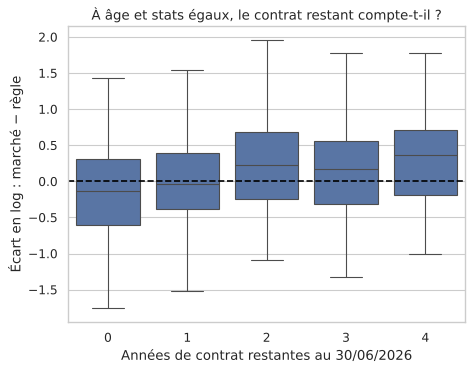

       ecart_log_median  multiplicateur
duree                                  
0                 -0.14            0.87
1                 -0.03            0.97
2                  0.22            1.25
3                  0.17            1.18
4                  0.36            1.44


In [89]:
sns.boxplot(data=ok, x="duree", y="ecart_log", showfliers=False)
plt.axhline(0, color="black", linestyle="--")
plt.xlabel("Années de contrat restantes au 30/06/2026")
plt.ylabel("Écart en log : marché − règle")
plt.title("À âge et stats égaux, le contrat restant compte-t-il ?")
plt.show()
ecart_duree = ok.groupby("duree")["ecart_log"].median()
print(pd.DataFrame({"ecart_log_median": ecart_duree, "multiplicateur": np.exp(ecart_duree)}).round(2))

L'écart à la règle monte encore avec les années restantes. À âge, stats, poste et ligue égaux, un joueur sous contrat pour 4 ans vaut donc environ 1,65 fois un joueur en fin de contrat. L'hypothèse du début est confirmée : le marché paie le contrat, pas seulement le joueur. Un club qui vend un joueur encore sous contrat peut exiger une indemnité, un joueur en fin de contrat part gratuitement.

In [90]:
# Dernière vérification : le salaire

In [91]:
y_ok = ok["log_cote"]
ok["grand_club"] = ok["tm_club_name"].map(est_grand_club)
essais = {
    "règle seule": [],
    "+ années de contrat": ["annees_contrat"],
    "+ grand club": ["grand_club"],
    "+ contrat + grand club": ["annees_contrat", "grand_club"],
    "+ salaire": ["log_salaire"],
    "+ contrat + grand club + salaire": ["annees_contrat", "grand_club", "log_salaire"],
}
resultats = []
for nom, extra in essais.items():
    s = cross_val_score(LinearRegression(), ok[VARIABLES + extra], y_ok, cv=CV5, scoring="r2")
    resultats.append({"modèle": nom, "R² moyen": round(s.mean(), 3), "écart-type": round(s.std(), 3)})
resultats = pd.DataFrame(resultats)
print(resultats.to_string(index=False))

reg_contrat = LinearRegression().fit(ok[VARIABLES + ["annees_contrat", "grand_club"]], y_ok)
coef_an = reg_contrat.coef_[len(VARIABLES)]   # la colonne juste après les variables de la règle
print("une année de contrat en plus, à tout le reste égal : x", round(np.exp(coef_an), 2),
      "soit", round((np.exp(coef_an) - 1) * 100), "% de cote")

                          modèle  R² moyen  écart-type
                     règle seule     0.621       0.083
             + années de contrat     0.641       0.090
                    + grand club     0.726       0.050
          + contrat + grand club     0.736       0.054
                       + salaire     0.800       0.063
+ contrat + grand club + salaire     0.813       0.053
une année de contrat en plus, à tout le reste égal : x 1.14 soit 14 % de cote


Sur les 719 joueurs qui ont un salaire (R² moyen sur 5 blocs) :
- la règle seule fait 0,62 ;
- les années de contrat ajoutent un peu (0,64), et une année de plus vaut environ +14 % de cote, à tout le reste égal ;
- le grand club ajoute beaucoup plus (0,73), et les deux ensemble font 0,74 ;
- le salaire fait monter à 0,80 (0,81 avec tout le reste), mais il dit en partie la même chose que la cote : un club paie cher le joueur qu'il a payé cher. Il aide à prédire, il n'explique pas.

Le contrat semble être un vrai facteur mais plus petit que le club. On ne change pas la règle affichée, pour la même raison que le grand club, le but est de voir ces écarts et non les cacher.

In [92]:
# comparaison salaire et cote

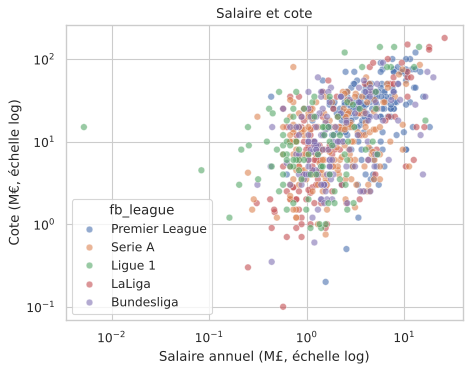

In [93]:
sns.scatterplot(data=ok, x="salaire_m", y="cote_m", hue="fb_league", hue_order=ORDRE_LIGUE, alpha=0.6)
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Salaire annuel (M£, échelle log)")
plt.ylabel("Cote (M€, échelle log)")
plt.title("Salaire et cote")
plt.show()

En échelle log, la pente se voit bien : plus le salaire est haut, plus la cote est haute, et les joueurs de Premier League sont en haut à droite.

In [94]:
base[["fb_id", "fb_name", "nom_norm", "fb_league", "cote_cible", "salaire_an_gbp", "annees_contrat"]].to_csv(
    DOSSIER / "joueurs_salaire.csv", index=False)
modele = modele.merge(sal[["nom_norm", "fb_league", "salaire_an_gbp", "annees_contrat"]], on=["nom_norm", "fb_league"], how="left")
# Pour Power BI : mêmes 13 premières colonnes qu'avant, puis les nouvelles
modele["ecart_euro"] = modele["cote_cible"] - modele["cote_predite"]
modele["ecart_pct"] = modele["ecart_euro"] / modele["cote_predite"]
modele[["id_projet", "fb_id", "tm_id", "fb_name", "fb_league", "fb_position", "age", "tm_club_name",
        "fb_minutes", "cote_cible", "cote_predite", "ecart_euro", "ecart_pct",
        "ecart_log", "multiplicateur", "grand_club", "salaire_an_gbp", "annees_contrat"]].to_csv(
    DOSSIER / "joueurs_modele.csv", index=False)
print("exports : joueurs_salaire.csv, joueurs_modele.csv")

exports : joueurs_salaire.csv, joueurs_modele.csv


## Instagram — 100 joueurs relevés le 15/09/2026

Je ne cherche pas à dire si les abonnés font le prix ou si le prix fait les abonnés. Avec un seul relevé, je ne peux pas. Je prends les followers comme un indicateur de visibilité, à mettre à côté de la cote, pas comme une cause.

In [95]:
insta = charger_csv("panel_insta_100 .csv", sep=";", skiprows=1)
insta["ig_followers"] = insta["followers_insta"].map(followers_vers_nombre)
print(len(insta), "lignes,", insta["ig_followers"].isna().sum(), "sans followers")
print(insta.loc[insta["ig_followers"].isna(), ["fb_name", "followers_insta"]])

insta["fb_id"] = insta["fb_id"].astype(int)
insta = insta.merge(joueurs[["fb_id", "tm_nationalite"]], on="fb_id", how="left")
print("sans nationalité :", insta["tm_nationalite"].isna().sum())

insta["tranche_age"] = pd.cut(
    insta["age_ans"], bins=[0, 22, 25, 29, 33, 50],
    labels=["16-21", "22-24", "25-28", "29-32", "33+"], right=False)

100 lignes, 1 sans followers
                fb_name followers_insta
62  Quilindschy Hartman             NaN
sans nationalité : 0


In [96]:
print("médiane des followers par ligue")
for lig in ORDRE_LIGUE:
    print(" ", lig, insta.loc[insta["fb_league"] == lig, "ig_followers"].median())
print("médiane des followers par poste")
for p in ORDRE_POSTE:
    print(" ", p, insta.loc[insta["fb_position"] == p, "ig_followers"].median())
print(insta.groupby("tranche_age", observed=False)["ig_followers"].agg(["count", "median"]))

médiane des followers par ligue
  Premier League 800000.0
  Serie A 197000.0
  Ligue 1 93500.0
  LaLiga 74450.0
  Bundesliga 27500.0
médiane des followers par poste
  F 1355500.0
  M 161000.0
  D 86300.0
  G 233000.0
             count    median
tranche_age                 
16-21            7  143000.0
22-24           34   72800.0
25-28           35  233000.0
29-32           11  292000.0
33+             12  320000.0


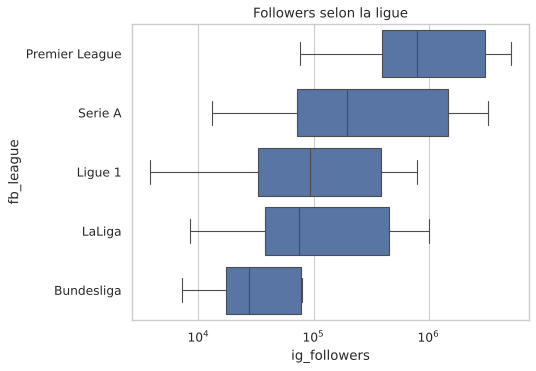

In [97]:
sns.boxplot(data=insta, y="fb_league", x="ig_followers", order=ORDRE_LIGUE, showfliers=False)
plt.xscale("log")
plt.title("Followers selon la ligue")
plt.show()

La Premier League est à part, médiane autour de 800 000 abonnés. La Serie A est large, du petit compte au très suivi (médiane 197 000). Ligue 1 et Liga se ressemblent (entre 75 000 et 95 000). La Bundesliga est en dessous, vers 27 500.
L'échelle est en log : un cran, c'est dix fois plus d'abonnés. Ça va dans le même sens que les cotes (même si ce n'est qu'un panel de 100) : le championnat anglais concentre aussi la visibilité.

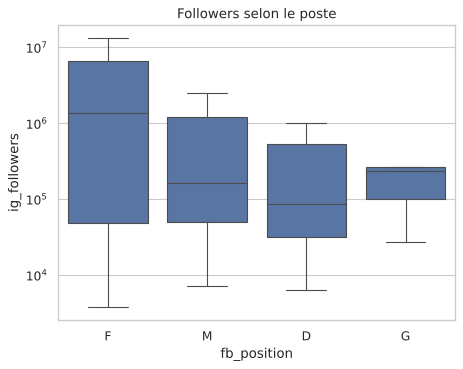

In [98]:
sns.boxplot(data=insta, x="fb_position", y="ig_followers", order=ORDRE_POSTE, showfliers=False)
plt.yscale("log")
plt.title("Followers selon le poste")
plt.show()

Les attaquants sont beaucoup plus suivis (médiane 1,36 million). Les gardiens ne sont pas les plus bas : médiane 233 000, contre 161 000 pour les milieux et 86 000 pour les défenseurs. Ça ne recopie pas exactement l'ordre des cotes.

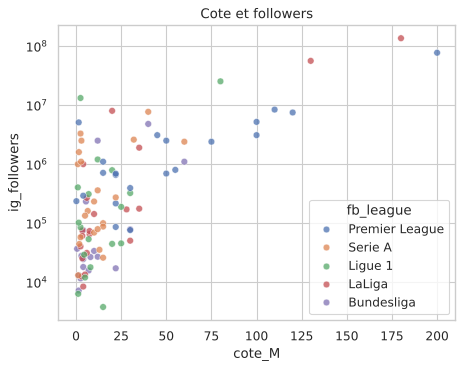

In [99]:
sns.scatterplot(data=insta, x="cote_M", y="ig_followers", hue="fb_league", hue_order=ORDRE_LIGUE, alpha=0.75)
plt.yscale("log")
plt.title("Cote et followers")
plt.show()

Les stars sont en haut à droite : chères, et très suivies. Le reste est tassé en bas à gauche, sous 25 M€, avec des comptes qui vont de quelques milliers à quelques centaines de milliers d'abonnés. Entre les deux, ça ne s'aligne pas parfaitement : à 30 ou 40 M€, certains sont aussi suivis que des joueurs à 80.

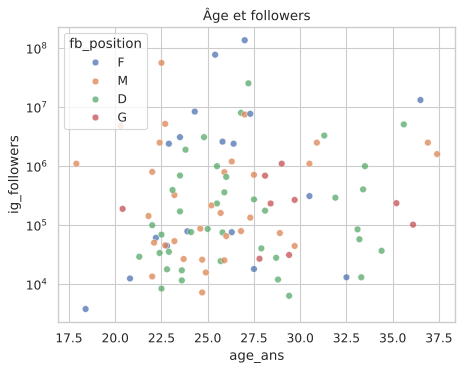

In [100]:
sns.scatterplot(data=insta, x="age_ans", y="ig_followers", hue="fb_position", hue_order=ORDRE_POSTE, alpha=0.75)
plt.yscale("log")
plt.title("Âge et followers")
plt.show()

L'âge ne trie pas les abonnés. À 20 ans comme à 35, on trouve des comptes à 10 000 et des comptes à plusieurs millions. Sur ce panel, le poste se voit plus que l'âge.

### Les followers et l'écart à la règle

La visibilité explique-t-elle une partie de ce que la règle ne voit pas ? On recolle chaque compte à son écart en log.

joueurs du panel avec un écart : 99
corrélation de rang followers / écart : 0.53
                 count  median  multiplicateur
tiers_followers                               
peu suivis          33   -0.55            0.58
moyens              33   -0.04            0.96
très suivis         33    0.56            1.74


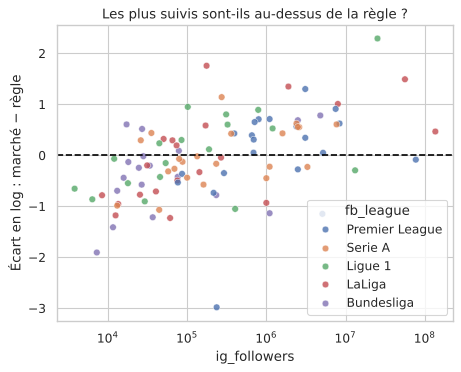

In [101]:
insta = insta.merge(modele[["fb_id", "ecart_log", "grand_club"]], on="fb_id", how="left")
panel = insta.dropna(subset=["ig_followers", "ecart_log"]).copy()
print("joueurs du panel avec un écart :", len(panel))
print("corrélation de rang followers / écart :", round(panel[["ig_followers", "ecart_log"]].corr(method="spearman").iloc[0, 1], 2))

panel["tiers_followers"] = pd.qcut(panel["ig_followers"], 3, labels=["peu suivis", "moyens", "très suivis"])
res = panel.groupby("tiers_followers", observed=False)["ecart_log"].agg(["count", "median"])
res["multiplicateur"] = np.exp(res["median"])
print(res.round(2))

sns.scatterplot(data=panel, x="ig_followers", y="ecart_log", hue="fb_league", hue_order=ORDRE_LIGUE, alpha=0.8)
plt.xscale("log")
plt.axhline(0, color="black", linestyle="--")
plt.ylabel("Écart en log : marché − règle")
plt.title("Les plus suivis sont-ils au-dessus de la règle ?")
plt.show()
insta.to_csv(DOSSIER / "panel_insta_100_clean.csv", index=False)

Sur les 99 comptes, plus un joueur est suivi, plus le marché le paie au-dessus de la règle (corrélation de rang 0,53). Le tiers le moins suivi est à ×0,58 de la règle, le tiers le plus suivi à ×1,74.
La visibilité accompagne donc ce que la règle ne voit pas. Trois limites : le panel est choisi à la main (pas au hasard), c'est un seul relevé, et les grands clubs ont à la fois plus d'abonnés et des cotes plus hautes. On ne peut pas dire ici que les abonnés font le prix.

## Panel au hasard (démonstration de la fonction)

In [102]:
demo = extraire_panel(modele, n=100)
print(demo.groupby(["fb_league", "tranche_age"], observed=False).size().unstack(fill_value=0))
print(demo[["fb_name", "fb_league", "fb_position", "age"]].head(10).round(1))

tranche_age     16-21  22-24  25-28  29-32  33+
fb_league                                      
Bundesliga          3      3      6      4    2
LaLiga              1      6      8      6    4
Ligue 1             0      6      5      3    2
Premier League      1      7      7      3    3
Serie A             0      7      6      5    2
              fb_name       fb_league fb_position   age
707     Youssef Maleh         Serie A           M  27.9
1151  Boubacar Traoré         Ligue 1           M  24.9
485       Nacho Vidal          LaLiga           D  31.4
49         Pau Torres  Premier League           D  29.5
912     Romano Schmid      Bundesliga           M  26.4
771      Yan Diomande      Bundesliga           F  19.6
433      Isaac Romero          LaLiga           F  26.1
170         Nick Pope  Premier League           G  34.2
174        Ilia Gruev  Premier League           M  26.1
333   Mikel Oyarzabal          LaLiga           F  29.2


## Recommandations : trois listes de travail

La règle se trompe en moyenne d'un facteur 1,6 : un écart n'est un signal qu'au-delà de ×0,5 ou ×2. Les listes ci-dessous sont des listes de joueurs à **visionner**, pas des listes d'achats : la règle ne voit ni le niveau tactique, ni les blessures.

In [103]:
print("erreur typique de la règle : facteur", round(np.exp(modele["ecart_log"].abs().median()), 2))
print("part des joueurs au-delà de ×0,5 ou ×2 :", round(((modele["multiplicateur"] < 0.5) | (modele["multiplicateur"] > 2)).mean(), 3))

cols = ["fb_name", "fb_position", "tm_club_name", "age", "cote_cible", "cote_predite", "multiplicateur", "annees_contrat"]

# 1. Acheter : jeunes titulaires hors grand club, payés moins de la moitié de la règle
acheter = modele[(modele["age"] <= 25) & (modele["fb_minutes"] >= 1800)
                 & (modele["grand_club"] == 0) & (modele["multiplicateur"] < 0.5)].sort_values("multiplicateur")
print("\n1. À visionner en priorité :", len(acheter), "joueurs")
print(acheter[cols].round(2).to_string(index=False))

# 2. Négocier : hors grand club, payés plus de 3 fois la règle
negocier = modele[(modele["grand_club"] == 0) & (modele["fb_minutes"] >= 1800)
                  & (modele["multiplicateur"] >= 3)].sort_values("multiplicateur", ascending=False)
print("\n2. Surcoût à justifier (×3 et plus, hors grand club) :", len(negocier), "joueurs")
print(negocier[cols].round(2).to_string(index=False))

# 3. Fin de contrat : titulaires de 27 ans ou moins, 1 an de contrat ou moins
fin = modele[(modele["annees_contrat"] <= 1) & (modele["age"] <= 27)
             & (modele["fb_minutes"] >= 1800)].sort_values("multiplicateur")
print("\n3. Titulaires en fin de contrat (1 an ou moins) :", len(fin), "joueurs")
print(fin[cols].round(2).head(10).to_string(index=False))

erreur typique de la règle : facteur 1.6
part des joueurs au-delà de ×0,5 ou ×2 : 0.315

1. À visionner en priorité : 16 joueurs
              fb_name fb_position                   tm_club_name   age  cote_cible  cote_predite  multiplicateur  annees_contrat
  Filippo Terracciano           D                   US Cremonese 23.39   4500000.0   27466563.56            0.16             2.0
         Danilo Veiga           D                       US Lecce 23.76   2500000.0   14861463.71            0.17             NaN
       Samuele Angori           M             Pisa Sporting Club 22.73   4500000.0   22915758.07            0.20             NaN
   Arijon Ibrahimović           M 1. Fußballclub Heidenheim 1846 20.55  10000000.0   45654016.57            0.22             1.0
           Hugo Bueno           D        Wolverhampton Wanderers 23.78  12000000.0   47358175.39            0.25             NaN
     Jonathan Fischer           G                        FC Metz 24.64   2000000.0    6982975.51 

## Test complémentaire : un panel plus large aurait-il donné une meilleure règle ?

On refait la même règle sur les 8 championnats du fichier FBref (Big 5 + Portugal, Pays-Bas, Turquie).

In [104]:
MAP_TM = {"Premier League": "GB1", "LaLiga": "ES1", "Serie A": "IT1", "Bundesliga": "L1", "Ligue 1": "FR1",
          "Liga Portugal": "PO1", "Eredivisie": "NL1", "Super Lig": "TR1"}

def r2_panel(ligues):
    codes = [MAP_TM[l] for l in ligues]
    t = players[(players["last_season"] >= 2024) & players["current_club_domestic_competition_id"].isin(codes)].copy()
    v = valuations[valuations["date"].between("2025-08-01", "2026-07-31")].sort_values("date").groupby("player_id").tail(1)
    t = t.merge(v[["player_id", "market_value_in_eur"]].rename(columns={"market_value_in_eur": "cote_saison"}), on="player_id", how="left")
    t["cote"] = t["cote_saison"].fillna(t["market_value_in_eur"])
    t["nom_norm"] = t["name"].map(norm_nom)
    t["naissance"] = pd.to_datetime(t["date_of_birth"], errors="coerce")
    t = t.rename(columns={"current_club_domestic_competition_id": "code", "position": "tm_pos"})
    f = stats.merge(profils.drop(columns="league"), on="player_id")
    f = f[f["league"].isin(ligues) & (f["minutes_played"] >= 900) & f["position"].notna()].copy()
    f["nom_norm"] = f["name"].map(norm_nom)
    f["code"] = f["league"].map(MAP_TM)
    f["tm_pos"] = f["position"].map({"F": "Attack", "M": "Midfield", "D": "Defender", "G": "Goalkeeper"})
    j = f.merge(t[["nom_norm", "code", "tm_pos", "cote", "naissance"]], on=["nom_norm", "code", "tm_pos"])
    j["age"] = (DATE_REF - j["naissance"]).dt.days / 365.25
    j = j[j["age"].notna() & j["cote"].notna()].copy()
    y_p = np.log(j["cote"].clip(lower=100_000))
    for nom, col in [("buts_90", "goals"), ("xg_90", "expected_goals"), ("pd_90", "assists"), ("xa_90", "expected_assists"),
                     ("tac_90", "tackles"), ("int_90", "interceptions"), ("arr_90", "saves")]:
        j[nom] = (j[col] / j["minutes_played"] * 90).fillna(0)
    base = j[["buts_90", "xg_90", "pd_90", "xa_90", "tac_90", "int_90", "arr_90", "age", "minutes_played"]]
    base = base.join(pd.get_dummies(j["position"], prefix="p", drop_first=True, dtype=int))
    avec_ligue = base.join(pd.get_dummies(j["league"], prefix="l", drop_first=True, dtype=int))
    return (len(j), cross_val_score(LinearRegression(), avec_ligue, y_p, cv=CV5).mean(),
            cross_val_score(LinearRegression(), base, y_p, cv=CV5).mean())

for nom, ligues in [("Big 5", ORDRE_LIGUE),
                    ("8 championnats", ORDRE_LIGUE + ["Liga Portugal", "Eredivisie", "Super Lig"]),
                    ("3 ajoutés seuls", ["Liga Portugal", "Eredivisie", "Super Lig"])]:
    n, r2, r2_sans = r2_panel(ligues)
    print(f"{nom:16s} {n:5d} joueurs | R² {r2:.2f} | R² sans la variable ligue {r2_sans:.2f}")

Big 5             1160 joueurs | R² 0.64 | R² sans la variable ligue 0.53
8 championnats    1731 joueurs | R² 0.68 | R² sans la variable ligue 0.36
3 ajoutés seuls    571 joueurs | R² 0.47 | R² sans la variable ligue 0.43


Avec 8 championnats, le R² monte de 0,64 à 0,68, mais seulement grâce à la variable ligue : sans elle, il tombe à 0,36 (0,53 sur le Big 5). Sur les trois championnats ajoutés seuls, la règle n'explique que 47 % de la cote. Garder le Big 5 donne un marché plus homogène et plus pertinent pour un club qui y recrute.

## Conclusion

Règle : Stats par 90 minutes, poste, ligue et âge expliquent environ 64 % de la cote en log sur des joueurs non vus (5 blocs mélangés). La régression linéaire fait mieux que la forêt (0,64 contre 0,61) et reste lisible. Ce n'est pas un prix de transfert, c'est un repère pour le milieu de tableau.

Apprentissage : La Premier League multiplie la cote par 2,6. Chaque année d'âge enlève 17 %. Les stats offensives (xA, buts) comptent ; côté défense, les interceptions comptent (+25 % par interception/90), les tacles non. 

Ce que la règle ne voit pas (testé une variable à la fois) :
- grand club : ×2,8 à profil égal, R² de 0,64 à 0,73
- contrat restant : environ +14 % par année, et un joueur à 4 ans de contrat vaut environ 1,65 fois un joueur en fin de contrat, à âge égal. L'hypothèse du contrat est confirmée, mais l'effet est plus petit que celui du club
- salaire : suit la cote (R² 0,81 avec lui), mais on suppose qu'il en est surtout le reflet
- visibilité Instagram : le tiers le plus suivi est à 1,7 fois la règle, le moins suivi à 0,6 fois, sur un panel de 100 et un seul relevé.

On laisse ces facteurs hors de la règle affichée pour que les écarts restent visibles : un Upamecano à 12 fois sa valeur « statistique », c'est justement ce que le projet veut montrer.

Limites : Jointures sur le nom (82 % pour Transfermarkt, 62 % pour les salaires), contrats après 2030 absents, salaires estimés par SalarySport, un seul relevé Instagram.